# Random Forest e SHAP para predição de AVC

Extensão acadêmica de Dritsas e Trigka (2022), [DOI 10.3390/s22134670](https://doi.org/10.3390/s22134670). O arquivo CSV fornecido produz 4.194 adultos (`age > 18`), não os 3.254 relatados no artigo. Este notebook usa divisão estratificada **antes** de imputação/SMOTENC. O teste conserva a prevalência original. O repositório de [Alberto Eusebio](https://github.com/AlbertoEusebio/Brain-Stroke-Prediction) serviu somente como referência auxiliar para a ideia de usar SMOTENC com dados mistos; o código abaixo é próprio.

**Alvo:** `stroke=1`, histórico de AVC no dataset. A análise não valida risco prospectivo nem uso clínico. [Gibson et al. (2026)](https://doi.org/10.1186/s12916-026-04981-y) identificaram falta de procedência verificável e anomalias neste CSV; consulte o [README](../README.md) para a discussão completa.

In [1]:
from importlib.metadata import version
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import Image, display

# Localiza a raiz do projeto ao executar pela raiz ou por notebooks/.
ROOT = Path.cwd() if (Path.cwd() / 'healthcare-dataset-stroke-data.csv').is_file() else Path.cwd().parent
if not (ROOT / 'healthcare-dataset-stroke-data.csv').is_file():
    raise FileNotFoundError('Execute o notebook pela raiz do projeto ou pela pasta notebooks/.')
# Permite importar as funções auditáveis do módulo compartilhado.
sys.path.insert(0, str(ROOT))

from stroke_xai import (
    FEATURE_LABELS, RANDOM_STATE, build_pipeline, display_feature_names,
    evaluate, grouped_shap_importance,
    load_adults, positive_shap_values, split_adults, transform_for_rf,
)

# Define onde ler o CSV e onde guardar resultados reproduzíveis.
DATA_PATH = ROOT / 'healthcare-dataset-stroke-data.csv'
FIGURES = ROOT / 'figures'
RESULTS = ROOT / 'results'
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
# Mostra as versões e a semente usadas nesta execução.
print('Versões:', {name: version(name) for name in
                   ['pandas', 'scikit-learn', 'imbalanced-learn', 'shap', 'matplotlib']})
print('random_state:', RANDOM_STATE)

D:\Usuario\Documentos\GitHub\XAI - AVC\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Versões: {'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'imbalanced-learn': '0.14.2', 'shap': '0.54.1', 'matplotlib': '3.11.2'}
random_state: 42


## 1. Coorte e divisão

Mantemos as dez variáveis do artigo, inclusive `Unknown` em tabagismo e o único `Other` em gênero. `id` serve apenas para rastreabilidade; não entra no modelo. A divisão ocorre antes de qualquer transformação que aprende com dados.

In [2]:
# Filtra adultos e separa o teste antes de imputação ou SMOTENC.
X, y, ids = load_adults(DATA_PATH)
X_train, X_test, y_train, y_test, id_train, id_test = split_adults(X, y, ids)
# Confere a coorte e impede que os mesmos IDs apareçam em treino e teste.
assert len(X) == 4194 and int(y.sum()) == 247
assert len(X_train) == 3355 and len(X_test) == 839
assert set(id_train).isdisjoint(set(id_test))
# Registra suporte, prevalência e IMC ausente de cada parte.
print('Coorte:', len(X), 'positivos:', int(y.sum()))
display(pd.DataFrame({
    'conjunto': ['treino', 'teste'],
    'n': [len(X_train), len(X_test)],
    'stroke=1': [int(y_train.sum()), int(y_test.sum())],
    'prevalência': [y_train.mean(), y_test.mean()],
}))
print('BMI ausente no treino/teste:', int(X_train.bmi.isna().sum()), int(X_test.bmi.isna().sum()))

Coorte: 4194 positivos: 247


,conjunto,n,stroke=1,prevalência
0,treino,3355,198,0.059016
1,teste,839,49,0.058403


BMI ausente no treino/teste: 144 36


## 2. Treino sem vazamento

O `imblearn.Pipeline` ajusta a mediana e o `SMOTENC` apenas no treino. `SMOTENC` trata sete atributos categóricos, incluindo indicadores binários. Depois da reamostragem, o `OneHotEncoder` prepara a entrada do Random Forest. O mesmo pipeline faz predição no teste sem reamostragem. Configuração fixa: 200 árvores, `random_state=42`, limiar de classificação padrão de 0,5; sem busca de hiperparâmetros pelo teste.

In [3]:
# O pipeline ajusta imputação, SMOTENC, codificação e RF apenas com X_train.
model = build_pipeline()
model.fit(X_train, y_train)
# Recupera o classificador ajustado; esta mesma instância será explicada pelo SHAP.
rf = model.named_steps['rf']
assert rf.classes_.tolist() == [0, 1]
# Confere quantos positivos sintéticos foram adicionados no treino.
smote_counts = model.named_steps['smote'].sampling_strategy_
print('Classes do RF:', rf.classes_.tolist())
print('Amostras sintéticas adicionadas somente ao treino:', smote_counts)
print('Entradas codificadas do RF:', rf.n_features_in_)

Classes do RF: [0, 1]
Amostras sintéticas adicionadas somente ao treino: OrderedDict({np.int64(1): np.int64(2959)})
Entradas codificadas do RF: 22


## 3. Avaliação no teste original

Precisão, recall e F1 abaixo referem-se à classe positiva. A AUC-ROC usa `predict_proba(stroke=1)`, não os rótulos previstos. A Tabela 2 do artigo relata métricas **médias** em validação cruzada de 10 dobras no conjunto já balanceado (6.148 instâncias), em WEKA. Logo, seus valores são contexto, não uma meta diretamente comparável ao teste deste notebook.

In [4]:
# Calcula métricas da classe 1 em registros originais do teste.
metrics = evaluate(model, X_train, y_train, X_test, y_test)
metrics_dict = metrics.to_dict()
# Mostra os números do artigo como referência, com protocolo distinto do nosso.
comparison = pd.DataFrame([
    {'protocolo': 'Dritsas e Trigka, Tabela 2 (médias; CV no balanceado)',
     'precision': 0.966, 'recall': 0.966, 'f1': 0.966, 'auc_roc': 0.986, 'accuracy': 0.97},
    {'protocolo': 'Este trabalho (stroke=1; teste original estratificado)',
     'precision': metrics.precision, 'recall': metrics.recall, 'f1': metrics.f1,
     'auc_roc': metrics.auc_roc, 'accuracy': metrics.accuracy},
])
display(comparison.round(3))
# A matriz evidencia positivos perdidos e falsos alertas ocultos pela acurácia.
display(pd.DataFrame([[metrics.tn, metrics.fp], [metrics.fn, metrics.tp]],
                     index=['real 0', 'real 1'], columns=['previsto 0', 'previsto 1']))
print('Suporte no teste:', {'stroke=0': metrics.n_test - metrics.positives_test,
                            'stroke=1': metrics.positives_test})
# Exporta os valores usados na documentação e na apresentação.
(RESULTS / 'metrics.json').write_text(
    json.dumps(metrics_dict, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

,protocolo,precision,recall,f1,auc_roc,accuracy
0,"Dritsas e Trigka, Tabela 2 (médias; CV no bala...",0.966,0.966,0.966,0.986,0.970
1,Este trabalho (stroke=1; teste original estrat...,0.120,0.184,0.145,0.755,0.874


,previsto 0,previsto 1
real 0,724,66
real 1,40,9


Suporte no teste: {'stroke=0': 790, 'stroke=1': 49}


286

## 4. SHAP global da classe `stroke=1`

Explicamos uma amostra reprodutível de 200 **registros originais do teste, não sintetizados por nós**, no espaço de 22 atributos codificados recebido pelo RF. `TreeExplainer` usa `tree_path_dependent`, sem dados do teste como background. Para este Random Forest, a saída `raw` equivale às probabilidades por classe, algo verificado numericamente abaixo. O valor-base vem do modelo treinado com SMOTENC e fica próximo de 0,5; **as probabilidades não foram calibradas para a prevalência real e não são riscos clínicos individuais**. O beeswarm mostra importância e direção das contribuições das variáveis codificadas; as barras agregam categorias da mesma variável original **somando as contribuições por registro antes da média de valores absolutos**.

Formato retornado pelo SHAP: (200, 22, 2)


Valor-base para stroke=1: 0.49979490022172945
Erro máximo da soma SHAP vs. predict_proba: 5.88418203051333e-15
Registros originais explicados: 200


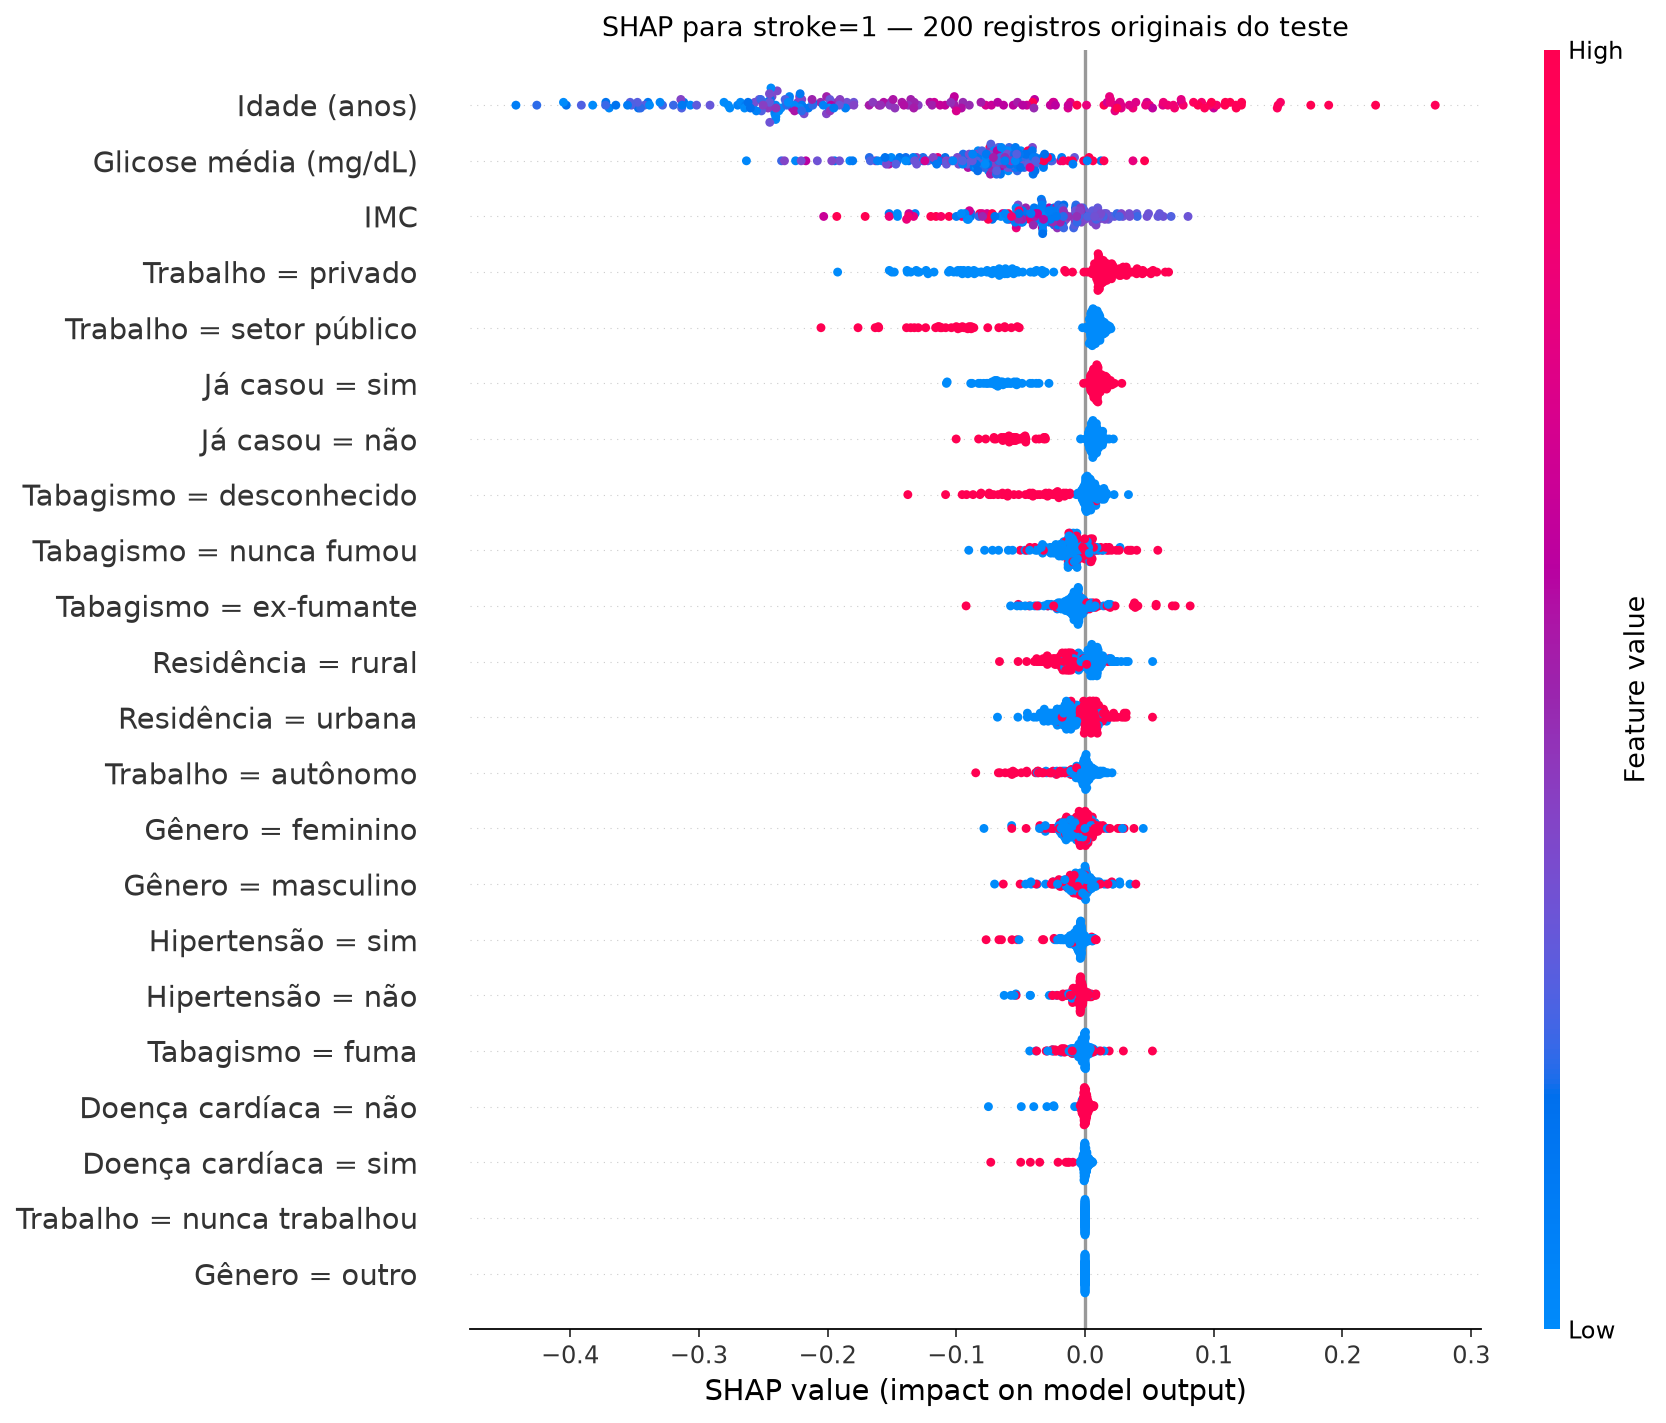

,média |SHAP|
age,0.176444
avg_glucose_level,0.081577
work_type,0.076053
smoking_status,0.043793
bmi,0.043128
ever_married,0.041623
Residence_type,0.026956
gender,0.020334
hypertension,0.015502
heart_disease,0.005172


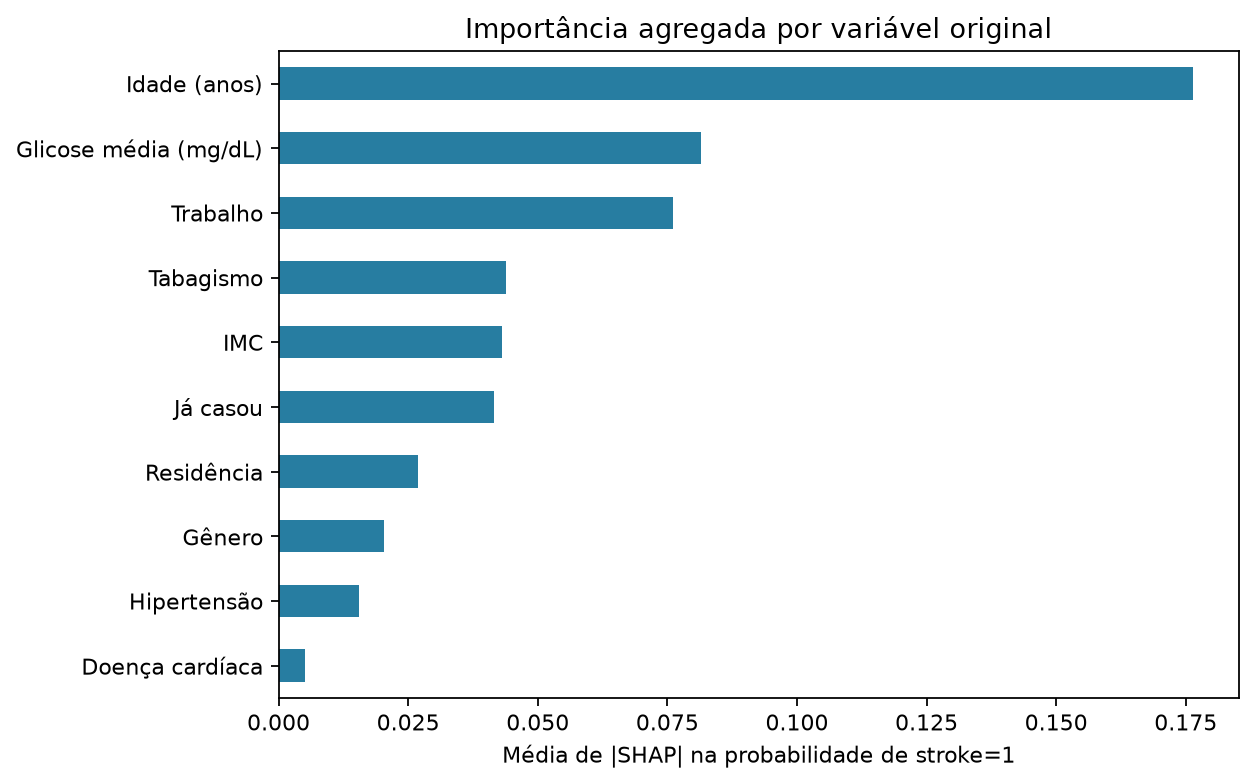

In [5]:
# Amostra fixa de linhas originais do teste; não treina nem reamostra o explainer.
X_explain = X_test.sample(n=min(200, len(X_test)), random_state=RANDOM_STATE)
encoded_explain = transform_for_rf(model, X_explain)
# TreeExplainer recebe o RF já ajustado e explica sua saída de classe.
explainer = shap.TreeExplainer(
    rf, feature_perturbation='tree_path_dependent', model_output='raw')
# Inspeciona o formato, que varia entre versões do SHAP.
raw_shap = explainer.shap_values(encoded_explain)
print('Formato retornado pelo SHAP:',
      [part.shape for part in raw_shap] if isinstance(raw_shap, list) else np.shape(raw_shap))
# Seleciona explicitamente stroke=1; evita confundir as duas classes.
values, base_value = positive_shap_values(explainer, encoded_explain, rf.classes_)
probabilities = model.predict_proba(X_explain)[:, list(rf.classes_).index(1)]
# Verifica aditividade: valor-base + SHAP deve reconstruir predict_proba.
max_error = float(np.max(np.abs(base_value + values.sum(axis=1) - probabilities)))
assert max_error < 1e-6
print('Valor-base para stroke=1:', base_value)
print('Erro máximo da soma SHAP vs. predict_proba:', max_error)
print('Registros originais explicados:', len(X_explain))

# Usa rótulos legíveis na mesma ordem das 22 colunas recebidas pelo RF.
display_names = display_feature_names(model)
assert len(display_names) == encoded_explain.shape[1]
encoded_display = encoded_explain.copy()
encoded_display.columns = display_names
# Beeswarm global: magnitude, sinal e dispersão de cada contribuição.
shap.summary_plot(values, encoded_display, show=False, max_display=22,
                  plot_size=(11, 9))
plt.title('SHAP para stroke=1 — 200 registros originais do teste')
plt.tight_layout()
plt.savefig(FIGURES / 'shap_summary_stroke1.png', dpi=160, bbox_inches='tight')
plt.close()
display(Image(filename=str(FIGURES / 'shap_summary_stroke1.png')))

# Agrupa dummies por variável antes da média absoluta; salva tabela e barras.
importance = grouped_shap_importance(values, model)
display(importance.rename('média |SHAP|').to_frame())
importance.rename('media_abs_shap').to_csv(RESULTS / 'importancia_shap.csv',
                                          header=True, encoding='utf-8')
fig, ax = plt.subplots(figsize=(8, 5))
importance.rename(index=FEATURE_LABELS).sort_values().plot.barh(ax=ax, color='#277da1')
ax.set_xlabel('Média de |SHAP| na probabilidade de stroke=1')
ax.set_title('Importância agregada por variável original')
fig.tight_layout()
fig.savefig(FIGURES / 'shap_importancia_agrupada.png', dpi=160, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(FIGURES / 'shap_importancia_agrupada.png')))

## 5. Explicações locais

Selecionamos de forma determinística o verdadeiro positivo com maior probabilidade prevista e, como contraste, o falso negativo com **menor** probabilidade prevista, se existir. Ambos são registros originais do CSV no teste. Em cada waterfall, vermelho aumenta e azul reduz a saída do RF para `stroke=1`. Essas contribuições explicam o modelo para um registro, não a causa médica de um AVC. As probabilidades não foram calibradas.

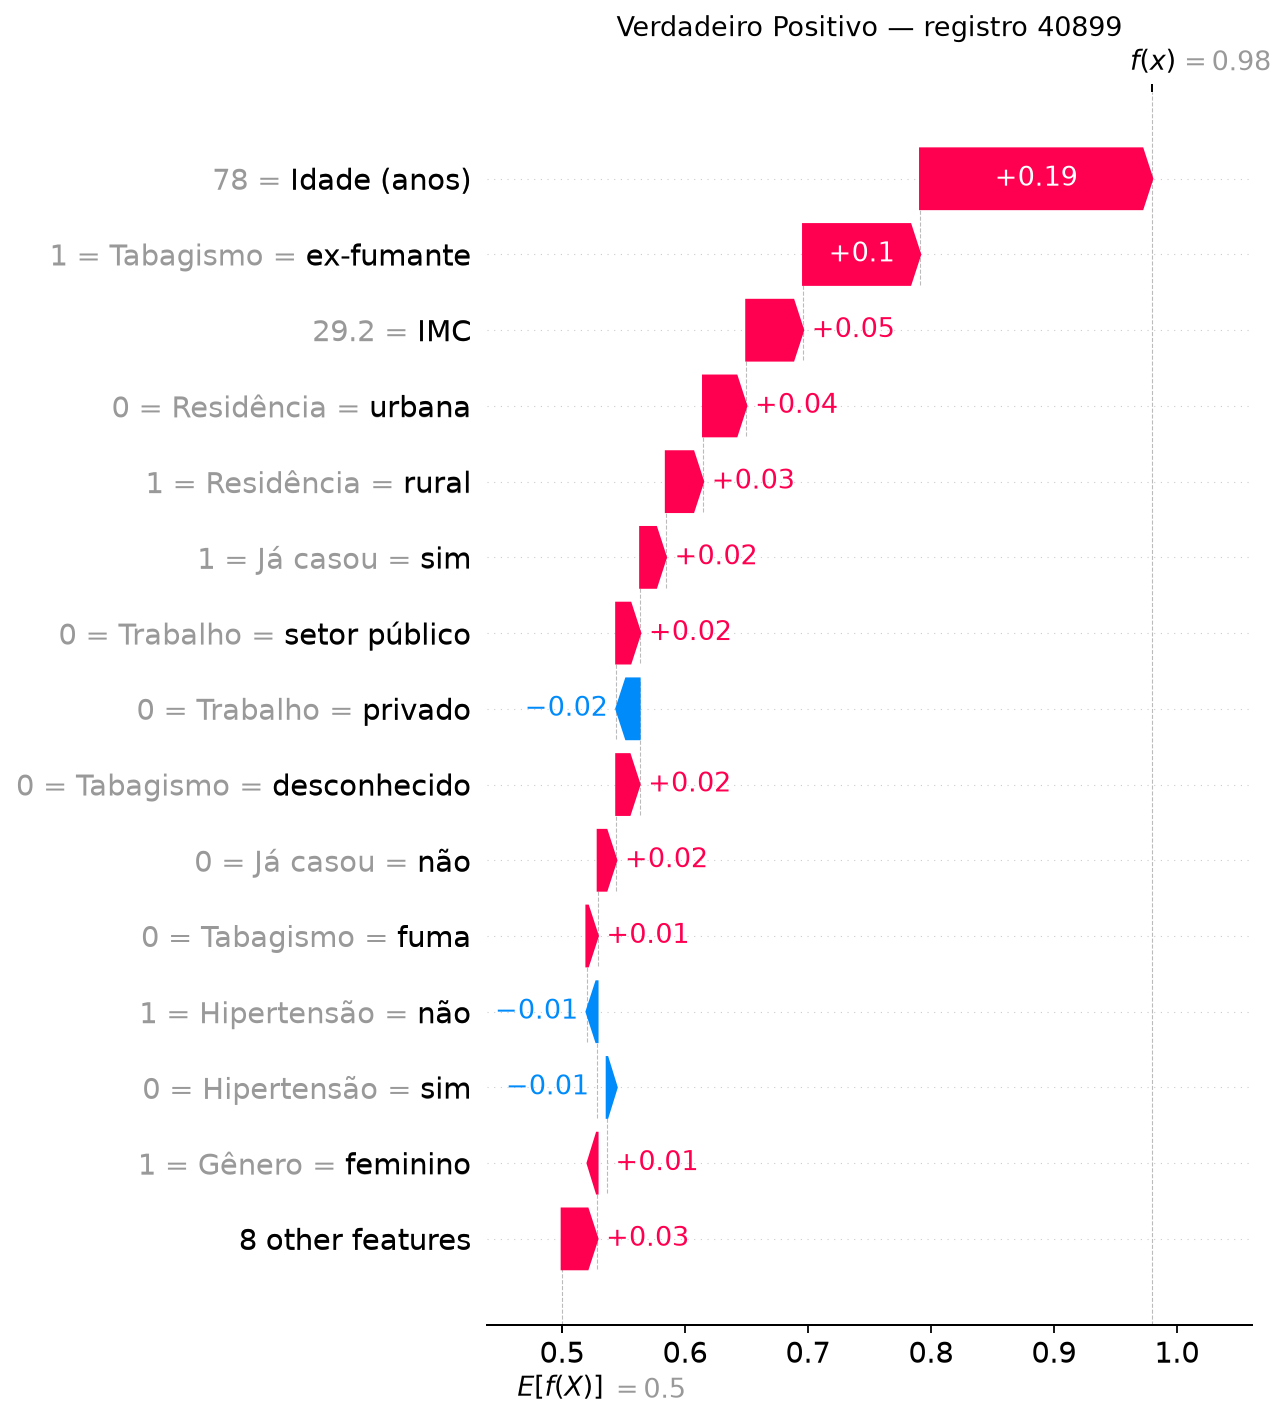

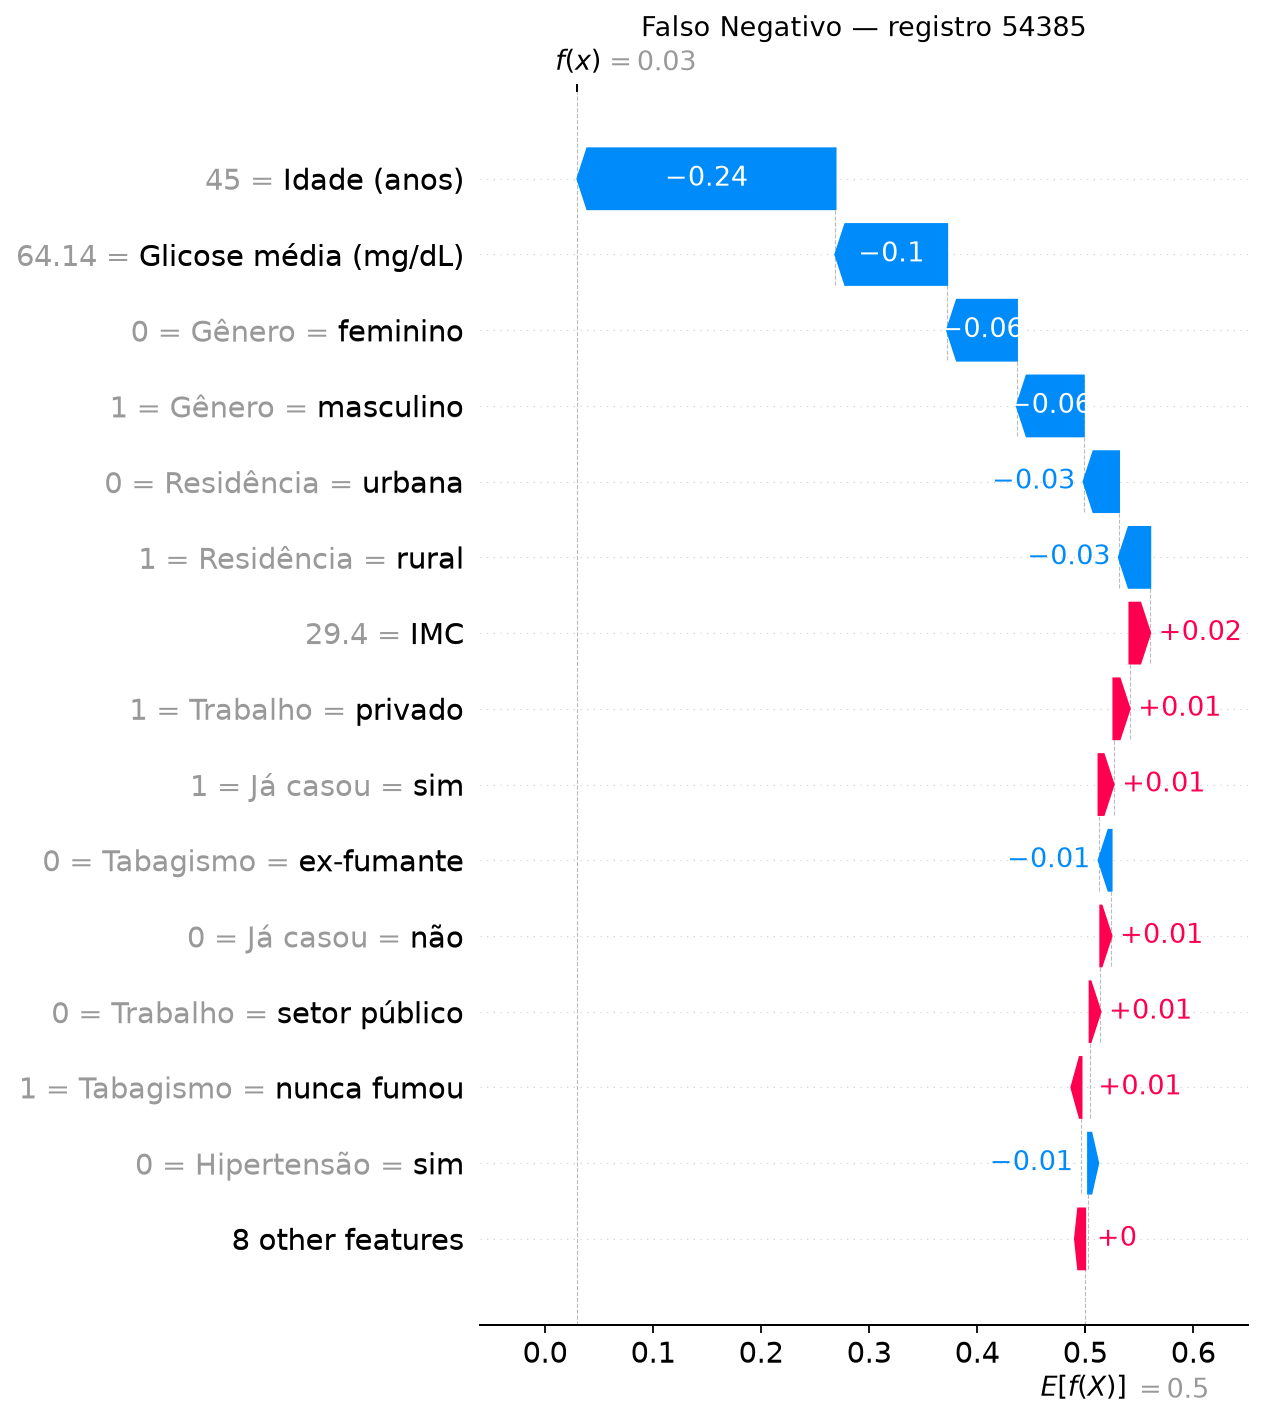

,tipo,id,real,previsto,probabilidade_stroke_1
0,verdadeiro_positivo,40899,1,1,0.98
1,falso_negativo,54385,1,0,0.03


258

In [6]:
# Identifica acertos e erros positivos usando as previsões no teste intocado.
test_probabilities = model.predict_proba(X_test)[:, 1]
test_predictions = model.predict(X_test)
truth = y_test.to_numpy()
true_positive = np.flatnonzero((truth == 1) & (test_predictions == 1))
false_negative = np.flatnonzero((truth == 1) & (test_predictions == 0))
# Escolhe um verdadeiro positivo e um falso negativo de modo determinístico.
selected = []
if len(true_positive):
    selected.append(('verdadeiro_positivo', true_positive[np.argmax(test_probabilities[true_positive])]))
if len(false_negative):
    selected.append(('falso_negativo', false_negative[np.argmin(test_probabilities[false_negative])]))
if not selected:
    raise RuntimeError('Nenhum caso positivo disponível para a explicação local.')

# Aplica somente os transformadores já ajustados e seleciona a classe positiva.
positions = [int(position) for _, position in selected]
X_local = X_test.iloc[positions]
encoded_local = transform_for_rf(model, X_local)
local_values, local_base = positive_shap_values(explainer, encoded_local, rf.classes_)
# Confere novamente a soma das contribuições para cada caso local.
assert np.allclose(local_base + local_values.sum(axis=1),
                   model.predict_proba(X_local)[:, 1], atol=1e-6)
case_rows = []
# Cada waterfall decompõe uma previsão; IDs e saídas ficam registrados em JSON.
for i, (kind, position) in enumerate(selected):
    position = int(position)
    case_rows.append({'tipo': kind, 'id': int(id_test.iloc[position]),
                      'real': int(truth[position]), 'previsto': int(test_predictions[position]),
                      'probabilidade_stroke_1': float(test_probabilities[position])})
    explanation = shap.Explanation(
        values=local_values[i], base_values=local_base,
        data=encoded_local.iloc[i].to_numpy(),
        feature_names=display_names)
    shap.plots.waterfall(explanation, max_display=15, show=False)
    plt.title(f'{kind.replace("_", " ").title()} — registro {int(id_test.iloc[position])}')
    plt.tight_layout()
    image_path = FIGURES / f'shap_waterfall_{kind}.png'
    plt.savefig(image_path, dpi=160, bbox_inches='tight')
    plt.close()
    display(Image(filename=str(image_path)))
display(pd.DataFrame(case_rows))
(RESULTS / 'casos_locais.json').write_text(
    json.dumps(case_rows, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

## 6. Leitura clínica e limites

Os valores acima descrevem **a importância para este modelo**, não a força causal de fatores clínicos. Idade, hipertensão, doença cardíaca, obesidade, diabetes e tabagismo são reconhecidos como fatores associados ao AVC pelo [CDC](https://www.cdc.gov/stroke/risk-factors/). `avg_glucose_level` não diagnostica diabetes; `bmi` não mede adiposidade diretamente. Variáveis sociais, como estado civil e trabalho, podem atuar como marcadores indiretos e exigem cautela. A importância baixa de hipertensão no SHAP, se ocorrer, não invalida sua relevância clínica: reflete este conjunto, o modelo e correlações entre variáveis. O alvo indica AVC prévio, sem seguimento temporal; portanto, o resultado não deve ser anunciado como risco futuro individual validado.

A procedência deste CSV é contestada; a verificação de aditividade confirma a explicação **da saída do RF**, não a autenticidade dos registros nem validade clínica. Para a discussão dos números e das inconsistências com o artigo, consulte o [README](../README.md).